In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Load final cleaned and feature-engineered dataset
df = pd.read_csv(
    '/content/BikeRental_Cleaned_Feature_Engineered.csv'
)

# Convert date column to datetime
df['dteday'] = pd.to_datetime(df['dteday'], errors='coerce')

# Remove rows with missing date or target
df = df.dropna(subset=['dteday', 'cnt'])

# Sort records chronologically
df = df.sort_values(['dteday', 'hr']).reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Season Categories:", df['season'].unique())
print("Target Variable: cnt")

Dataset Shape: (17379, 27)
Missing Values: 0
Season Categories: ['spring' 'fall' 'summer' 'winter']
Target Variable: cnt


In [3]:
#Select input features and target variable
# Target variable
y = df['cnt'].astype(float)

# Remove columns that should not be used for prediction
X = df.drop(
    columns=[
        'cnt',
        'casual',
        'registered',
        'instant',
        'dteday',
        'year_month'
    ],
    errors='ignore'
)

print("Input Features:", X.shape)
print("Target Variable:", y.shape)
print("\nSelected Features:")
print(X.columns.tolist())

Input Features: (17379, 21)
Target Variable: (17379,)

Selected Features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'day', 'day_of_year', 'is_weekend', 'hour_period', 'is_peak_hour', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [4]:
#Split the dataset into training and testing sets
# Chronological 80:20 split
split_point = int(len(X) * 0.80)

X_train = X.iloc[:split_point].copy()
X_test = X.iloc[split_point:].copy()

y_train = y.iloc[:split_point].copy()
y_test = y.iloc[split_point:].copy()

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Date Range:")
print(df['dteday'].iloc[0],
      "to",
      df['dteday'].iloc[split_point - 1])

print("\nTesting Date Range:")
print(df['dteday'].iloc[split_point],
      "to",
      df['dteday'].iloc[-1])

Training Records: 13903
Testing Records: 3476

Training Date Range:
2011-01-01 00:00:00 to 2012-08-07 00:00:00

Testing Date Range:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


In [5]:
#Data preprocessing
# Identify categorical columns
categorical_names = [
    'season',
    'mnth',
    'hr',
    'holiday',
    'weekday',
    'workingday',
    'weathersit',
    'hour_period'
]

categorical_columns = [
    col for col in X_train.columns
    if col in categorical_names
    or X_train[col].dtype in ['object', 'category', 'bool']
]

# Identify numerical columns
numerical_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
]

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

# Numerical preprocessing with scaling
numeric_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing without scaling
numeric_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocessing for MLR and SVR
scaled_preprocessor = ColumnTransformer([
    ('numeric', numeric_scaled, numerical_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])

# Preprocessing for tree-based models
tree_preprocessor = ColumnTransformer([
    ('numeric', numeric_unscaled, numerical_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])

# Time series cross-validation
time_cv = TimeSeriesSplit(n_splits=3)

Categorical Columns: ['season', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'hour_period']
Numerical Columns: ['yr', 'temp', 'atemp', 'hum', 'windspeed', 'day', 'day_of_year', 'is_weekend', 'is_peak_hour', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [6]:
#Multiple Linear Regression (MLR)
# Create MLR pipeline
mlr_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', LinearRegression())
])

# Train the model
mlr_model = mlr_pipeline.fit(X_train, y_train)

# Predict on test data
mlr_pred = mlr_model.predict(X_test)

# Calculate evaluation metrics
mlr_mae = mean_absolute_error(y_test, mlr_pred)
mlr_mse = mean_squared_error(y_test, mlr_pred)
mlr_rmse = np.sqrt(mlr_mse)
mlr_r2 = r2_score(y_test, mlr_pred)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("----------------------------------")
print("MAE:", round(mlr_mae, 2))
print("MSE:", round(mlr_mse, 2))
print("RMSE:", round(mlr_rmse, 2))
print("R2 Score:", round(mlr_r2, 4))

MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------
MAE: 101.15
MSE: 21273.99
RMSE: 145.86
R2 Score: 0.5624


In [7]:
#Support Vector Regression (SVR)
# Create SVR pipeline
svr_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', SVR(kernel='rbf', cache_size=1000))
])

# Define hyperparameters
svr_params = {
    'model__C': [1, 10],
    'model__epsilon': [0.1, 0.2],
    'model__gamma': ['scale']
}

# Hyperparameter tuning using GridSearchCV
svr_grid = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_params,
    scoring='neg_mean_absolute_error',
    cv=time_cv,
    n_jobs=-1
)

# Train and tune the model
svr_grid.fit(X_train, y_train)

# Get the best model
svr_model = svr_grid.best_estimator_

# Cross-validation MAE
svr_cv_mae = -svr_grid.best_score_

# Predict on test data
svr_pred = svr_model.predict(X_test)

# Calculate evaluation metrics
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_mse = mean_squared_error(y_test, svr_pred)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, svr_pred)

print("SUPPORT VECTOR REGRESSION RESULTS")
print("---------------------------------")
print("Best Parameters:", svr_grid.best_params_)
print("Cross-Validation MAE:", round(svr_cv_mae, 2))
print("MAE:", round(svr_mae, 2))
print("MSE:", round(svr_mse, 2))
print("RMSE:", round(svr_rmse, 2))
print("R2 Score:", round(svr_r2, 4))

SUPPORT VECTOR REGRESSION RESULTS
---------------------------------
Best Parameters: {'model__C': 10, 'model__epsilon': 0.2, 'model__gamma': 'scale'}
Cross-Validation MAE: 84.1
MAE: 65.23
MSE: 10142.39
RMSE: 100.71
R2 Score: 0.7914


In [9]:
# Random Forest Regression

rf_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Reduced hyperparameter combinations
rf_params = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [10],
    'model__min_samples_leaf': [2]
}

# Hyperparameter tuning
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=3),
    n_jobs=1
)

# Train model
rf_grid.fit(X_train, y_train)

# Best model
rf_model = rf_grid.best_estimator_

# Cross-validation MAE
rf_cv_mae = -rf_grid.best_score_

# Predictions
rf_pred = rf_model.predict(X_test)

# Evaluation
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST RESULTS")
print("Best Parameters:", rf_grid.best_params_)
print("Cross-Validation MAE:", round(rf_cv_mae, 2))
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))


RANDOM FOREST RESULTS
Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 50}
Cross-Validation MAE: 57.9
MAE: 50.94
MSE: 5952.22
RMSE: 77.15
R2 Score: 0.8776


In [11]:
# Gradient Boosting Regression

gb_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

# Reduced hyperparameter combinations
gb_params = {
    'model__n_estimators': [50, 100],
    'model__learning_rate': [0.1],
    'model__max_depth': [2]
}

# Hyperparameter tuning
gb_grid = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_params,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=3),
    n_jobs=-1
)

# Train the model
gb_grid.fit(X_train, y_train)

# Best model
gb_model = gb_grid.best_estimator_

# Cross-validation MAE
gb_cv_mae = -gb_grid.best_score_

# Predictions
gb_pred = gb_model.predict(X_test)

# Evaluation metrics
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("GRADIENT BOOSTING RESULTS")
print("-------------------------")
print("Best Parameters:", gb_grid.best_params_)
print("Cross-Validation MAE:", round(gb_cv_mae, 2))
print("MAE:", round(gb_mae, 2))
print("MSE:", round(gb_mse, 2))
print("RMSE:", round(gb_rmse, 2))
print("R2 Score:", round(gb_r2, 4))

GRADIENT BOOSTING RESULTS
-------------------------
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
Cross-Validation MAE: 77.77
MAE: 83.98
MSE: 13764.04
RMSE: 117.32
R2 Score: 0.7169


In [12]:
#Calculate MLR cross-validation MAE
#calculate cross-validation MAE for MLR so that all four algorithms can be compared fairly.
mlr_cv_scores = cross_val_score(
    mlr_pipeline,
    X_train,
    y_train,
    cv=time_cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

mlr_cv_mae = -mlr_cv_scores.mean()

print("MLR Cross-Validation MAE:", round(mlr_cv_mae, 2))

MLR Cross-Validation MAE: 105.6


In [13]:
#Compare all four algorithms
comparison = pd.DataFrame({
    'Algorithm': [
        'Multiple Linear Regression',
        'SVR',
        'Random Forest',
        'Gradient Boosting'
    ],

    'CV MAE': [
        mlr_cv_mae,
        svr_cv_mae,
        rf_cv_mae,
        gb_cv_mae
    ],

    'Test MAE': [
        mlr_mae,
        svr_mae,
        rf_mae,
        gb_mae
    ],

    'Test MSE': [
        mlr_mse,
        svr_mse,
        rf_mse,
        gb_mse
    ],

    'Test RMSE': [
        mlr_rmse,
        svr_rmse,
        rf_rmse,
        gb_rmse
    ],

    'Test R2 Score': [
        mlr_r2,
        svr_r2,
        rf_r2,
        gb_r2
    ]
})

# Sort according to cross-validation MAE
comparison = comparison.sort_values(
    by='CV MAE'
).reset_index(drop=True)

display(comparison)

,Algorithm,CV MAE,Test MAE,Test MSE,Test RMSE,Test R2 Score
0,Random Forest,57.896906,50.940300,5952.217428,77.150615,0.877561
1,Gradient Boosting,77.771482,83.979992,13764.036485,117.320231,0.716868
2,SVR,84.098528,65.228501,10142.385801,100.709413,0.791367
3,Multiple Linear Regression,105.604361,101.152937,21273.988109,145.856053,0.562386


In [14]:
#Select the final model
# Store all trained models
models = {
    'Multiple Linear Regression': mlr_model,
    'SVR': svr_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

# Select the best model
best_model_name = comparison.loc[0, 'Algorithm']

final_model = models[best_model_name]

print("Best Performing Model:", best_model_name)
print("Cross-Validation MAE:",
      round(comparison.loc[0, 'CV MAE'], 2))


Best Performing Model: Random Forest
Cross-Validation MAE: 57.9


In [15]:
#Final model evaluation
# Predict using the selected final model
final_pred = final_model.predict(X_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, final_pred)
final_mse = mean_squared_error(y_test, final_pred)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, final_pred)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("Selected Model:", best_model_name)
print("MAE:", round(final_mae, 2))
print("MSE:", round(final_mse, 2))
print("RMSE:", round(final_rmse, 2))
print("R2 Score:", round(final_r2, 4))

FINAL MODEL EVALUATION
----------------------
Selected Model: Random Forest
MAE: 50.94
MSE: 5952.22
RMSE: 77.15
R2 Score: 0.8776


In [16]:
#Actual vs. predicted bike rentals
# Create actual and predicted comparison
test_results = pd.DataFrame({
    'Actual_Rentals': y_test.values,
    'Predicted_Rentals': np.round(final_pred).astype(int)
})

test_results['Error'] = (
    test_results['Actual_Rentals']
    - test_results['Predicted_Rentals']
)

test_results['Absolute_Error'] = (
    test_results['Error'].abs()
)

display(test_results.head(20))

,Actual_Rentals,Predicted_Rentals,Error,Absolute_Error
0,283.0,259,24.0,24.0
1,253.0,259,-6.0,6.0
2,261.0,259,2.0,2.0
3,306.0,260,46.0,46.0
4,445.0,334,111.0,111.0
5,868.0,762,106.0,106.0
6,814.0,766,48.0,48.0
7,610.0,565,45.0,45.0
8,448.0,422,26.0,26.0
9,317.0,267,50.0,50.0


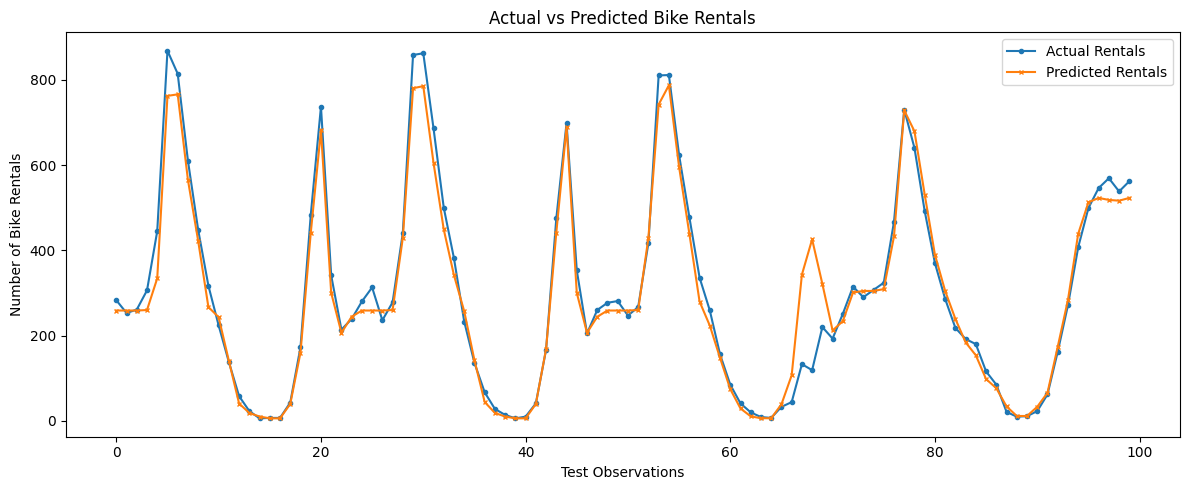

In [17]:
#Visualize actual vs. predicted rentals
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:100],
    label='Actual Rentals',
    marker='o',
    markersize=3
)

plt.plot(
    final_pred[:100],
    label='Predicted Rentals',
    marker='x',
    markersize=3
)

plt.title('Actual vs Predicted Bike Rentals')
plt.xlabel('Test Observations')
plt.ylabel('Number of Bike Rentals')
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Save the selected final model
with open('bike_rental_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

print("Final model saved successfully!")
print("File Name: bike_rental_model.pkl")
print("Selected Model:", best_model_name)

Final model saved successfully!
File Name: bike_rental_model.pkl
Selected Model: Random Forest
